In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn xgboost shap joblib

^C
Note: you may need to restart the kernel to use updated packages.
Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   --- ------------------------------------ 3.9/48.9 MB 29.8 MB/s eta 0:00:02
   -------- ------------------------------- 10.7/48.9 MB 35.9 MB/s eta 0:00:02
   -------- ------------------------------- 11.0/48.9 MB 21.8 MB/s eta 0:00:02
   ---------- ----------------------------- 12.6/48.9 MB 16.6 MB/s eta 0:00:03
   ----------- ---------------------------- 14.2/48.9 MB 14.7 MB/s eta 0:00:03
   ------------ --------------------------- 15.2/48.9 MB 13.4 MB/s eta 0:00:03
   ------------- -------------------------- 16.5/48.9 MB 11.9 MB/s eta 0:00:03
   -------------- ------------------------- 17.8/48.9 MB 11.2 MB/s eta 0:00:03
   --------------- ------------------------ 18.9/48.9 MB 10.5 MB/s eta 0:00:03
   ---------------- ----------------------- 19.9/48.9 MB 10.0 MB/s eta 0:

In [2]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")


Libraries imported successfully!


In [5]:
import os

print(os.getcwd())

C:\Users\Admin\FY 2026 PRO


In [6]:
import os

folder = r"C:\Users\Admin\FY 2026 PRO"

for file in os.listdir(folder):
    if file.endswith(".csv"):
        print(file)

hearing_loss_synthetic_dataset_10000_patients.csv


In [8]:
import pandas as pd
from tkinter import Tk, filedialog

root = Tk()
root.withdraw()
root.attributes("-topmost", True)

file_path = filedialog.askopenfilename(
    title="Select your hearing-loss dataset",
    filetypes=[("CSV files", "*.csv"), ("All files", "*.*")]
)

root.destroy()

if file_path:
    df = pd.read_csv(file_path)
    print("Dataset loaded successfully!")
    print("File:", file_path)
    print("Dataset shape:", df.shape)
    display(df.head())
else:
    print("No file selected.")

Dataset loaded successfully!
File: C:/Users/Admin/FY 2026 PRO/hearing_loss_synthetic_dataset_10000_patients.csv
Dataset shape: (10000, 76)


,patient_id,age_years,sex,visit_date,chief_complaint,hearing_duration_years,onset,progression,affected_ear,speech_difficulty,...,right_UCL_dBHL,left_UCL_dBHL,right_Rinne,left_Rinne,Weber,right_masking_required,left_masking_required,audiogram_reliability,audiometer_id,clinician_confirmed_severity
0,P00001,34,Female,2026-05-09,Tinnitus,4,Gradual,Progressive,Right,No,...,93.3,93.9,Negative,Negative,Midline,Yes,Yes,Good,AUDIO-01,Mild
1,P00002,59,Male,2026-05-31,Reduced hearing,5,Gradual,Static,Both,No,...,102.9,97.8,Negative,Negative,Left,Yes,Yes,Good,AUDIO-03,Moderate
2,P00003,87,Male,2026-05-07,Routine screening,4,Gradual,Fluctuating,Both,Yes,...,125.0,125.0,Positive,Positive,Midline,Yes,Yes,Good,AUDIO-01,Profound
3,P00004,24,Male,2026-07-20,Reduced hearing,3,Gradual,Progressive,Both,No,...,72.3,82.7,Positive,Positive,Midline,No,No,Acceptable,AUDIO-03,Normal
4,P00005,52,Female,2026-04-26,Reduced hearing,0,Gradual,Static,Left,No,...,102.2,93.8,Positive,Positive,Midline,No,No,Acceptable,AUDIO-02,Moderate


In [9]:
print("Number of patients:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of patients: 10000
Number of columns: 76


In [10]:
for i, col in enumerate(df.columns, start=1):
    print(i, col)
    

1 patient_id
2 age_years
3 sex
4 visit_date
5 chief_complaint
6 hearing_duration_years
7 onset
8 progression
9 affected_ear
10 speech_difficulty
11 tinnitus
12 tinnitus_type
13 vertigo_dizziness
14 ear_pain
15 ear_blocking
16 ear_discharge
17 recurrent_ear_infection
18 noise_exposure
19 noise_type
20 noise_hours_per_day
21 noise_exposure_years
22 family_history_hearing_loss
23 diabetes
24 hypertension
25 ototoxic_exposure
26 head_injury
27 previous_ear_surgery
28 congenital_hearing_issue
29 previous_hearing_aid
30 right_otoscopy
31 left_otoscopy
32 hearing_loss_type
33 right_250_AC_dBHL
34 left_250_AC_dBHL
35 right_500_AC_dBHL
36 left_500_AC_dBHL
37 right_1000_AC_dBHL
38 left_1000_AC_dBHL
39 right_2000_AC_dBHL
40 left_2000_AC_dBHL
41 right_4000_AC_dBHL
42 left_4000_AC_dBHL
43 right_8000_AC_dBHL
44 left_8000_AC_dBHL
45 right_250_BC_dBHL
46 left_250_BC_dBHL
47 right_500_BC_dBHL
48 left_500_BC_dBHL
49 right_1000_BC_dBHL
50 left_1000_BC_dBHL
51 right_2000_BC_dBHL
52 left_2000_BC_dBHL
53 ri

In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 76 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   patient_id                    10000 non-null  str    
 1   age_years                     10000 non-null  int64  
 2   sex                           10000 non-null  str    
 3   visit_date                    10000 non-null  str    
 4   chief_complaint               10000 non-null  str    
 5   hearing_duration_years        10000 non-null  int64  
 6   onset                         10000 non-null  str    
 7   progression                   10000 non-null  str    
 8   affected_ear                  10000 non-null  str    
 9   speech_difficulty             10000 non-null  str    
 10  tinnitus                      10000 non-null  str    
 11  tinnitus_type                 1086 non-null   str    
 12  vertigo_dizziness             10000 non-null  str    
 13  ear_pain     

In [12]:
missing = df.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing Values": missing,
    "Missing Percentage": (missing / len(df) * 100).round(2)
})

missing_summary = missing_summary[
    missing_summary["Missing Values"] > 0
].sort_values(by="Missing Percentage", ascending=False)

display(missing_summary)

,Missing Values,Missing Percentage
tinnitus_type,8914,89.14
noise_type,7452,74.52
right_250_BC_dBHL,570,5.70
right_UCL_dBHL,471,4.71
right_MCL_dBHL,464,4.64
left_250_BC_dBHL,429,4.29
left_MCL_dBHL,218,2.18
left_UCL_dBHL,200,2.00


In [13]:
print("Duplicate rows:", df.duplicated().sum())

print("Duplicate patient IDs:", df["patient_id"].duplicated().sum())

Duplicate rows: 0
Duplicate patient IDs: 0


In [14]:
target = "clinician_confirmed_severity"

print(df[target].value_counts())

print("\nClass percentages:")
print((df[target].value_counts(normalize=True) * 100).round(2))

clinician_confirmed_severity
Moderate             2831
Mild                 2061
Moderately Severe    2052
Severe               1380
Profound              921
Normal                755
Name: count, dtype: int64

Class percentages:
clinician_confirmed_severity
Moderate             28.31
Mild                 20.61
Moderately Severe    20.52
Severe               13.80
Profound              9.21
Normal                7.55
Name: proportion, dtype: float64


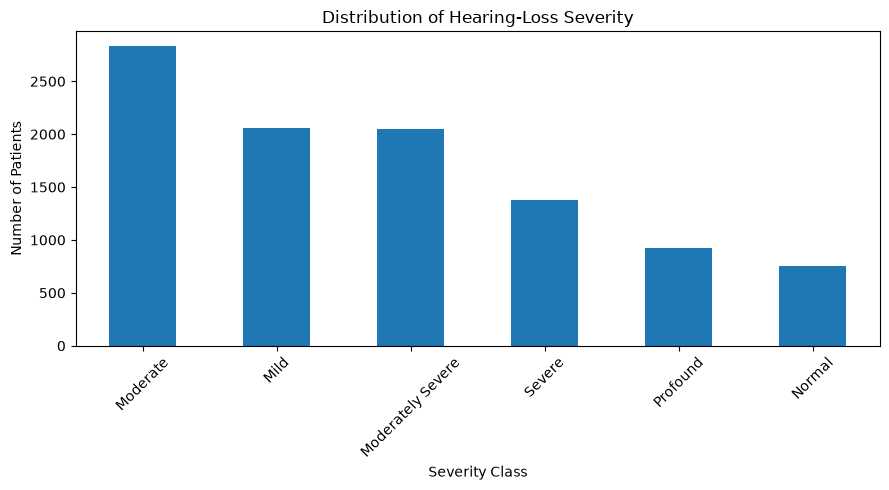

In [15]:
import matplotlib.pyplot as plt

df[target].value_counts().plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Distribution of Hearing-Loss Severity")
plt.xlabel("Severity Class")
plt.ylabel("Number of Patients")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [16]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
age_years,10000.0,52.281000,18.659048,5.0,37.000,52.0,66.000,90.0
hearing_duration_years,10000.0,5.624900,6.326753,0.0,1.000,4.0,8.000,35.0
noise_hours_per_day,10000.0,1.399830,2.697147,0.0,0.000,0.0,2.100,9.9
noise_exposure_years,10000.0,4.237700,8.262919,0.0,0.000,0.0,4.000,30.0
right_250_AC_dBHL,10000.0,54.268800,23.849252,-2.5,37.800,52.3,71.300,113.8
left_250_AC_dBHL,10000.0,53.578070,24.076881,2.2,35.000,50.5,70.100,115.3
right_500_AC_dBHL,10000.0,54.213420,23.327225,1.1,36.500,52.5,69.200,112.8
left_500_AC_dBHL,10000.0,53.238940,22.808365,7.2,36.000,50.3,68.800,113.6
right_1000_AC_dBHL,10000.0,53.428680,23.203403,-2.8,37.700,52.5,67.700,110.7
left_1000_AC_dBHL,10000.0,54.298720,23.682426,0.7,36.075,51.9,69.200,111.8


In [17]:
df_clean = df.copy()

print("Original dataset:", df.shape)
print("Working dataset:", df_clean.shape)

Original dataset: (10000, 76)
Working dataset: (10000, 76)


In [18]:
# Remove extra spaces from column names
df_clean.columns = df_clean.columns.str.strip()

# Remove leading and trailing spaces from text values
for col in df_clean.select_dtypes(include="object").columns:
    df_clean[col] = df_clean[col].str.strip()

# Convert empty strings into missing values
df_clean.replace(r"^\s*$", pd.NA, regex=True, inplace=True)

print("Text cleanup completed.")

C:\Users\Admin\AppData\Local\Temp\ipykernel_9588\2277616287.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df_clean.select_dtypes(include="object").columns:


Text cleanup completed.


In [18]:
# Remove extra spaces from column names
df_clean.columns = df_clean.columns.str.strip()

# Remove leading and trailing spaces from text values
for col in df_clean.select_dtypes(include="object").columns:
    df_clean[col] = df_clean[col].str.strip()

# Convert empty strings into missing values
df_clean.replace(r"^\s*$", pd.NA, regex=True, inplace=True)

print("Text cleanup completed.")

C:\Users\Admin\AppData\Local\Temp\ipykernel_9588\2277616287.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df_clean.select_dtypes(include="object").columns:


Text cleanup completed.


In [19]:
missing_summary = pd.DataFrame({
    "Missing Values": df_clean.isnull().sum(),
    "Missing Percentage": (
        df_clean.isnull().sum() / len(df_clean) * 100
    ).round(2)
})

display(
    missing_summary[missing_summary["Missing Values"] > 0]
    .sort_values("Missing Percentage", ascending=False)
)

,Missing Values,Missing Percentage
tinnitus_type,8914,89.14
noise_type,7452,74.52
right_250_BC_dBHL,570,5.70
right_UCL_dBHL,471,4.71
right_MCL_dBHL,464,4.64
left_250_BC_dBHL,429,4.29
left_MCL_dBHL,218,2.18
left_UCL_dBHL,200,2.00


In [20]:
print("Duplicate rows:", df_clean.duplicated().sum())
print("Duplicate patient IDs:", df_clean["patient_id"].duplicated().sum())

Duplicate rows: 0
Duplicate patient IDs: 0


In [21]:
df_clean["visit_date"] = pd.to_datetime(
    df_clean["visit_date"],
    errors="coerce"
)

print(df_clean["visit_date"].dtype)

datetime64[us]


In [22]:
target = "clinician_confirmed_severity"

print("Missing target values:", df_clean[target].isnull().sum())
print("\nSeverity classes:")
print(df_clean[target].value_counts(dropna=False))

Missing target values: 0

Severity classes:
clinician_confirmed_severity
Moderate             2831
Mild                 2061
Moderately Severe    2052
Severe               1380
Profound              921
Normal                755
Name: count, dtype: int64


In [23]:
df_clean.to_csv("hearing_loss_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")
print("Final shape:", df_clean.shape)

Cleaned dataset saved successfully!
Final shape: (10000, 76)


In [24]:
import pandas as pd
from sklearn.model_selection import train_test_split

target = "clinician_confirmed_severity"

# Exclude the target and identifiers that should not be model inputs
exclude_cols = [
    target,
    "patient_id",
    "visit_date",
    "audiometer_id"
]

X = df_clean.drop(columns=exclude_cols, errors="ignore")
y = df_clean[target]

print("Input features:", X.shape)
print("Target:", y.shape)
print("\nTarget classes:")
print(y.value_counts())

Input features: (10000, 72)
Target: (10000,)

Target classes:
clinician_confirmed_severity
Moderate             2831
Mild                 2061
Moderately Severe    2052
Severe               1380
Profound              921
Normal                755
Name: count, dtype: int64


In [25]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training features: (8000, 72)
Testing features: (2000, 72)

Training target distribution:
clinician_confirmed_severity
Moderate             2265
Mild                 1649
Moderately Severe    1641
Severe               1104
Profound              737
Normal                604
Name: count, dtype: int64

Testing target distribution:
clinician_confirmed_severity
Moderate             566
Mild                 412
Moderately Severe    411
Severe               276
Profound             184
Normal               151
Name: count, dtype: int64


In [26]:
numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

print("\nNumerical columns:")
print(numeric_features)

print("\nCategorical columns:")
print(categorical_features)

Numerical features: 40
Categorical features: 32

Numerical columns:
['age_years', 'hearing_duration_years', 'noise_hours_per_day', 'noise_exposure_years', 'right_250_AC_dBHL', 'left_250_AC_dBHL', 'right_500_AC_dBHL', 'left_500_AC_dBHL', 'right_1000_AC_dBHL', 'left_1000_AC_dBHL', 'right_2000_AC_dBHL', 'left_2000_AC_dBHL', 'right_4000_AC_dBHL', 'left_4000_AC_dBHL', 'right_8000_AC_dBHL', 'left_8000_AC_dBHL', 'right_250_BC_dBHL', 'left_250_BC_dBHL', 'right_500_BC_dBHL', 'left_500_BC_dBHL', 'right_1000_BC_dBHL', 'left_1000_BC_dBHL', 'right_2000_BC_dBHL', 'left_2000_BC_dBHL', 'right_4000_BC_dBHL', 'left_4000_BC_dBHL', 'right_PTA3_dBHL', 'left_PTA3_dBHL', 'right_PTA4_dBHL', 'left_PTA4_dBHL', 'right_SRT_dBHL', 'left_SRT_dBHL', 'right_SDT_dBHL', 'left_SDT_dBHL', 'right_WRS_percent', 'left_WRS_percent', 'right_MCL_dBHL', 'left_MCL_dBHL', 'right_UCL_dBHL', 'left_UCL_dBHL']

Categorical columns:
['sex', 'chief_complaint', 'onset', 'progression', 'affected_ear', 'speech_difficulty', 'tinnitus', 'ti

C:\Users\Admin\AppData\Local\Temp\ipykernel_9588\166501251.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(


In [27]:
print("Cleaned dataset:", df_clean.shape)
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Cleaned dataset: (10000, 76)
Training data: (8000, 72)
Testing data: (2000, 72)
Training labels: (8000,)
Testing labels: (2000,)


In [28]:
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("\nNumerical columns:", numeric_features)
print("\nCategorical columns:", categorical_features)

Numerical features: 40
Categorical features: 32

Numerical columns: ['age_years', 'hearing_duration_years', 'noise_hours_per_day', 'noise_exposure_years', 'right_250_AC_dBHL', 'left_250_AC_dBHL', 'right_500_AC_dBHL', 'left_500_AC_dBHL', 'right_1000_AC_dBHL', 'left_1000_AC_dBHL', 'right_2000_AC_dBHL', 'left_2000_AC_dBHL', 'right_4000_AC_dBHL', 'left_4000_AC_dBHL', 'right_8000_AC_dBHL', 'left_8000_AC_dBHL', 'right_250_BC_dBHL', 'left_250_BC_dBHL', 'right_500_BC_dBHL', 'left_500_BC_dBHL', 'right_1000_BC_dBHL', 'left_1000_BC_dBHL', 'right_2000_BC_dBHL', 'left_2000_BC_dBHL', 'right_4000_BC_dBHL', 'left_4000_BC_dBHL', 'right_PTA3_dBHL', 'left_PTA3_dBHL', 'right_PTA4_dBHL', 'left_PTA4_dBHL', 'right_SRT_dBHL', 'left_SRT_dBHL', 'right_SDT_dBHL', 'left_SDT_dBHL', 'right_WRS_percent', 'left_WRS_percent', 'right_MCL_dBHL', 'left_MCL_dBHL', 'right_UCL_dBHL', 'left_UCL_dBHL']

Categorical columns: ['sex', 'chief_complaint', 'onset', 'progression', 'affected_ear', 'speech_difficulty', 'tinnitus', 'ti

C:\Users\Admin\AppData\Local\Temp\ipykernel_9588\3433388451.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(


In [29]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [30]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

In [31]:
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

In [32]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

print("Preprocessing pipeline created.")

Preprocessing pipeline created.


In [33]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Processed training data:", X_train_processed.shape)
print("Processed testing data:", X_test_processed.shape)

Processed training data: (8000, 125)
Processed testing data: (2000, 125)


In [34]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

rf_model.fit(X_train_processed, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [35]:
y_pred = rf_model.predict(X_test_processed)

print("First 10 actual labels:")
print(y_test.iloc[:10].tolist())

print("\nFirst 10 predicted labels:")
print(y_pred[:10].tolist())

First 10 actual labels:
['Normal', 'Profound', 'Moderate', 'Mild', 'Normal', 'Mild', 'Moderately Severe', 'Moderately Severe', 'Severe', 'Moderate']

First 10 predicted labels:
['Normal', 'Profound', 'Moderate', 'Mild', 'Normal', 'Mild', 'Moderately Severe', 'Moderately Severe', 'Severe', 'Moderate']


In [36]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix
)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))

print(
    "Balanced accuracy:",
    round(balanced_accuracy_score(y_test, y_pred), 4)
)

print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 1.0
Balanced accuracy: 1.0

Classification report:
                   precision    recall  f1-score   support

             Mild       1.00      1.00      1.00       412
         Moderate       1.00      1.00      1.00       566
Moderately Severe       1.00      1.00      1.00       411
           Normal       1.00      1.00      1.00       151
         Profound       1.00      1.00      1.00       184
           Severe       1.00      1.00      1.00       276

         accuracy                           1.00      2000
        macro avg       1.00      1.00      1.00      2000
     weighted avg       1.00      1.00      1.00      2000



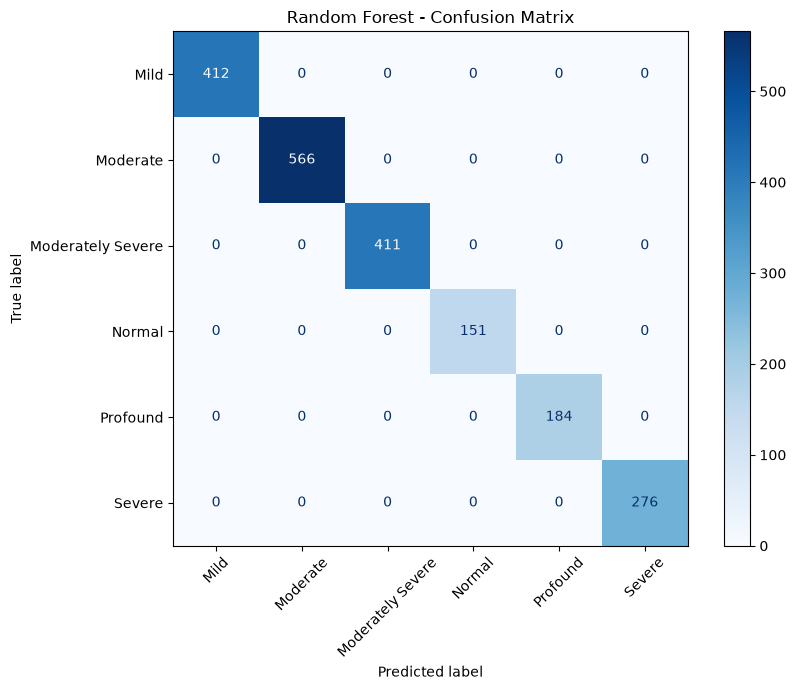

In [37]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=rf_model.classes_
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=rf_model.classes_
)

fig, ax = plt.subplots(figsize=(9, 7))
disp.plot(ax=ax, cmap="Blues", xticks_rotation=45)
plt.title("Random Forest - Confusion Matrix")
plt.tight_layout()
plt.show()

In [38]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Balanced Accuracy:", balanced_accuracy_score(y_test, y_pred))
print("Macro Precision:", precision_score(
    y_test, y_pred, average="macro", zero_division=0
))
print("Macro Recall:", recall_score(
    y_test, y_pred, average="macro", zero_division=0
))
print("Macro F1-score:", f1_score(
    y_test, y_pred, average="macro", zero_division=0
))

Accuracy: 1.0
Balanced Accuracy: 1.0
Macro Precision: 1.0
Macro Recall: 1.0
Macro F1-score: 1.0


In [39]:
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np

print("Test records:", len(y_test))
print("Correct predictions:", np.sum(y_test.to_numpy() == y_pred))
print("Incorrect predictions:", np.sum(y_test.to_numpy() != y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred, labels=rf_model.classes_))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Test records: 2000
Correct predictions: 2000
Incorrect predictions: 0

Confusion Matrix:
[[412   0   0   0   0   0]
 [  0 566   0   0   0   0]
 [  0   0 411   0   0   0]
 [  0   0   0 151   0   0]
 [  0   0   0   0 184   0]
 [  0   0   0   0   0 276]]

Classification Report:
                   precision    recall  f1-score   support

             Mild       1.00      1.00      1.00       412
         Moderate       1.00      1.00      1.00       566
Moderately Severe       1.00      1.00      1.00       411
           Normal       1.00      1.00      1.00       151
         Profound       1.00      1.00      1.00       184
           Severe       1.00      1.00      1.00       276

         accuracy                           1.00      2000
        macro avg       1.00      1.00      1.00      2000
     weighted avg       1.00      1.00      1.00      2000



In [40]:


from sklearn.base import clone
from sklearn.metrics import accuracy_score, balanced_accuracy_score

# Randomly shuffle the training labels
y_train_shuffled = y_train.sample(
    frac=1,
    random_state=42
).to_numpy()

# Create a fresh copy of the trained model's configuration
shuffled_model = clone(rf_model)

# Train using the shuffled labels
shuffled_model.fit(X_train_processed, y_train_shuffled)

# Predict on the original, unchanged test data
shuffled_pred = shuffled_model.predict(X_test_processed)

# Evaluate against the original test labels
print(
    "Shuffled-label accuracy:",
    round(accuracy_score(y_test, shuffled_pred), 4)
)

print(
    "Shuffled-label balanced accuracy:",
    round(balanced_accuracy_score(y_test, shuffled_pred), 4)
)

Shuffled-label accuracy: 0.157
Shuffled-label balanced accuracy: 0.1395


In [41]:
pta_cols = [
    "right_PTA3_dBHL",
    "left_PTA3_dBHL",
    "right_PTA4_dBHL",
    "left_PTA4_dBHL"
]

for col in pta_cols:
    if col in df_clean.columns:
        print(f"\n{col} by severity:")
        display(
            df_clean.groupby("clinician_confirmed_severity")[col]
            .agg(["count", "mean", "median", "min", "max"])
            .round(2)
        )


right_PTA3_dBHL by severity:


,count,mean,median,min,max
clinician_confirmed_severity,,,,,
Mild,2061,32.63,33.3,16.4,46.6
Moderate,2831,49.45,48.9,36.5,63.5
Moderately Severe,2052,64.52,64.2,49.3,79.7
Normal,755,17.40,16.8,2.3,31.3
Profound,921,100.11,99.2,88.6,110.7
Severe,1380,76.90,76.2,59.9,95.9



left_PTA3_dBHL by severity:


,count,mean,median,min,max
clinician_confirmed_severity,,,,,
Mild,2061,33.77,33.4,24.4,46.2
Moderate,2831,47.30,48.0,33.3,62.4
Moderately Severe,2052,65.12,63.7,52.0,78.4
Normal,755,18.44,19.7,10.2,29.0
Profound,921,100.69,100.7,85.8,111.6
Severe,1380,78.87,77.9,66.2,95.5



right_PTA4_dBHL by severity:


,count,mean,median,min,max
clinician_confirmed_severity,,,,,
Mild,2061,34.08,34.9,17.2,48.2
Moderate,2831,51.32,51.3,38.1,64.0
Moderately Severe,2052,66.07,65.9,52.7,80.0
Normal,755,19.37,17.5,7.6,33.4
Profound,921,101.49,100.6,89.8,111.8
Severe,1380,78.96,78.6,64.6,97.5



left_PTA4_dBHL by severity:


,count,mean,median,min,max
clinician_confirmed_severity,,,,,
Mild,2061,35.45,35.1,26.2,45.4
Moderate,2831,48.84,48.9,36.5,62.2
Moderately Severe,2052,66.37,65.8,55.8,78.1
Normal,755,19.43,19.9,9.7,29.1
Profound,921,102.27,102.3,87.5,112.8
Severe,1380,80.42,79.4,68.3,95.4


In [43]:
import pandas as pd

train_df = pd.read_csv(
    "hearing_loss_synthetic_train_8000.csv"
)

test_df = pd.read_csv(
    "hearing_loss_synthetic_test_2000.csv"
)

print(train_df.shape)
print(test_df.shape)

train_df.head()


(8000, 76)
(2000, 76)


,patient_id,age_years,sex,visit_date,chief_complaint,hearing_duration_years,onset,progression,affected_ear,speech_difficulty,...,left_MCL_dBHL,left_UCL_dBHL,left_Rinne,left_otoscopy,Weber,right_masking_required,left_masking_required,audiogram_reliability,audiometer_id,synthetic_severity_label
0,SYN-00001,43,Female,2023-05-29,Routine hearing assessment,5.0,Gradual,Static,Both,No,...,88.0,110.0,Positive,Normal,Midline,No,No,Good,AUD-13,Mild
1,SYN-00002,65,Male,2025-10-03,Difficulty hearing speech,5.2,Gradual,Static,Right,Yes,...,59.0,87.0,Positive,Normal,Lateralized Right,No,Yes,Good,AUD-15,Mild
2,SYN-00003,59,Female,2025-03-16,Routine hearing assessment,2.3,Gradual,Fluctuating,Both,No,...,45.0,110.0,Positive,Normal,Midline,No,Yes,Good,AUD-02,Mild
3,SYN-00004,40,Male,2023-12-11,Routine hearing assessment,12.6,Gradual,Static,Both,No,...,29.0,65.0,Positive,Normal,Midline,No,No,Good,AUD-11,Normal
4,SYN-00007,31,Male,2024-11-10,Gradual hearing decline,1.1,Sudden,Fluctuating,Both,No,...,70.0,103.0,Negative,Normal,Midline,No,Yes,Good,AUD-09,Moderate


In [44]:
import pandas as pd

train_df = pd.read_csv(
    r"C:\Users\Admin\FY 2026 PRO\hearing_loss_synthetic_train_8000.csv"
)

test_df = pd.read_csv(
    r"C:\Users\Admin\FY 2026 PRO\hearing_loss_synthetic_test_2000.csv"
)

print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)

Training shape: (8000, 76)
Testing shape: (2000, 76)


In [45]:
print("Training target distribution:")
print(train_df["synthetic_severity_label"].value_counts())

print("\nTesting target distribution:")
print(test_df["synthetic_severity_label"].value_counts())


Training target distribution:
synthetic_severity_label
Mild                 3652
Normal               1981
Moderate             1441
Moderately Severe     581
Severe                261
Profound               84
Name: count, dtype: int64

Testing target distribution:
synthetic_severity_label
Mild                 913
Normal               495
Moderate             360
Moderately Severe    145
Severe                66
Profound              21
Name: count, dtype: int64


In [46]:
import pandas as pd
import numpy as np

print("Libraries imported successfully!")


Libraries imported successfully!


In [47]:
print("Training target distribution:")
print(train_df["synthetic_severity_label"].value_counts())

print("\nTesting target distribution:")
print(test_df["synthetic_severity_label"].value_counts())

Training target distribution:
synthetic_severity_label
Mild                 3652
Normal               1981
Moderate             1441
Moderately Severe     581
Severe                261
Profound               84
Name: count, dtype: int64

Testing target distribution:
synthetic_severity_label
Mild                 913
Normal               495
Moderate             360
Moderately Severe    145
Severe                66
Profound              21
Name: count, dtype: int64


In [48]:
print("Number of columns:", len(train_df.columns))

for i, col in enumerate(train_df.columns, start=1):
    print(i, col)

Number of columns: 76
1 patient_id
2 age_years
3 sex
4 visit_date
5 chief_complaint
6 hearing_duration_years
7 onset
8 progression
9 affected_ear
10 speech_difficulty
11 tinnitus
12 tinnitus_type
13 vertigo_dizziness
14 ear_pain
15 ear_blocking
16 ear_discharge
17 recurrent_ear_infection
18 noise_exposure
19 noise_type
20 noise_hours_per_day
21 noise_exposure_years
22 family_history_hearing_loss
23 diabetes
24 hypertension
25 ototoxic_exposure
26 head_injury
27 previous_ear_surgery
28 congenital_hearing_issue
29 previous_hearing_aid
30 hearing_loss_type
31 right_250_AC_dBHL
32 right_250_BC_dBHL
33 right_500_AC_dBHL
34 right_500_BC_dBHL
35 right_1000_AC_dBHL
36 right_1000_BC_dBHL
37 right_2000_AC_dBHL
38 right_2000_BC_dBHL
39 right_4000_AC_dBHL
40 right_4000_BC_dBHL
41 right_8000_AC_dBHL
42 right_PTA3_dBHL
43 right_PTA4_dBHL
44 right_SRT_dBHL
45 right_SDT_dBHL
46 right_WRS_percent
47 right_MCL_dBHL
48 right_UCL_dBHL
49 right_Rinne
50 right_otoscopy
51 left_250_AC_dBHL
52 left_250_BC_dBH

In [49]:
target = "synthetic_severity_label"

X_train = train_df.drop(columns=[target])
y_train = train_df[target]

X_test = test_df.drop(columns=[target])
y_test = test_df[target]

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (8000, 75)
y_train: (8000,)
X_test: (2000, 75)
y_test: (2000,)


In [50]:
exclude_columns = [
    "patient_id",
    "visit_date",
    "audiometer_id"
]

X_train = X_train.drop(
    columns=exclude_columns,
    errors="ignore"
)

X_test = X_test.drop(
    columns=exclude_columns,
    errors="ignore"
)

print("X_train after removing identifiers:", X_train.shape)
print("X_test after removing identifiers:", X_test.shape)

X_train after removing identifiers: (8000, 72)
X_test after removing identifiers: (2000, 72)


In [51]:
numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Number of numerical features:", len(numeric_features))
print("Number of categorical features:", len(categorical_features))

print("\nNumerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Number of numerical features: 40
Number of categorical features: 32

Numerical features:
['age_years', 'hearing_duration_years', 'noise_hours_per_day', 'noise_exposure_years', 'right_250_AC_dBHL', 'right_250_BC_dBHL', 'right_500_AC_dBHL', 'right_500_BC_dBHL', 'right_1000_AC_dBHL', 'right_1000_BC_dBHL', 'right_2000_AC_dBHL', 'right_2000_BC_dBHL', 'right_4000_AC_dBHL', 'right_4000_BC_dBHL', 'right_8000_AC_dBHL', 'right_PTA3_dBHL', 'right_PTA4_dBHL', 'right_SRT_dBHL', 'right_SDT_dBHL', 'right_WRS_percent', 'right_MCL_dBHL', 'right_UCL_dBHL', 'left_250_AC_dBHL', 'left_250_BC_dBHL', 'left_500_AC_dBHL', 'left_500_BC_dBHL', 'left_1000_AC_dBHL', 'left_1000_BC_dBHL', 'left_2000_AC_dBHL', 'left_2000_BC_dBHL', 'left_4000_AC_dBHL', 'left_4000_BC_dBHL', 'left_8000_AC_dBHL', 'left_PTA3_dBHL', 'left_PTA4_dBHL', 'left_SRT_dBHL', 'left_SDT_dBHL', 'left_WRS_percent', 'left_MCL_dBHL', 'left_UCL_dBHL']

Categorical features:
['sex', 'chief_complaint', 'onset', 'progression', 'affected_ear', 'speech_diffic

C:\Users\Admin\AppData\Local\Temp\ipykernel_9588\3781357034.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(


In [52]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

In [53]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Processed training shape: (8000, 126)
Processed testing shape: (2000, 126)


In [54]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

rf_model.fit(
    X_train_processed,
    y_train
)

print("Random Forest training completed.")

Random Forest training completed.


In [55]:
y_pred = rf_model.predict(X_test_processed)

print("Predictions generated:", len(y_pred))

Predictions generated: 2000


In [56]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

accuracy = accuracy_score(y_test, y_pred)
balanced_acc = balanced_accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average="macro")
recall = recall_score(y_test, y_pred, average="macro")
macro_f1 = f1_score(y_test, y_pred, average="macro")

print("========== MODEL PERFORMANCE ==========")
print(f"Accuracy:           {accuracy:.4f}")
print(f"Balanced Accuracy:  {balanced_acc:.4f}")
print(f"Macro Precision:    {precision:.4f}")
print(f"Macro Recall:       {recall:.4f}")
print(f"Macro F1:           {macro_f1:.4f}")

========== MODEL PERFORMANCE ==========
Accuracy:           0.9120
Balanced Accuracy:  0.8970
Macro Precision:    0.9070
Macro Recall:       0.8970
Macro F1:           0.9013


In [57]:
print(classification_report(
    y_test,
    y_pred,
    digits=4
))

                   precision    recall  f1-score   support

             Mild     0.9459    0.9003    0.9226       913
         Moderate     0.8667    0.9028    0.8844       360
Moderately Severe     0.8958    0.8897    0.8927       145
           Normal     0.8939    0.9535    0.9228       495
         Profound     0.9474    0.8571    0.9000        21
           Severe     0.8923    0.8788    0.8855        66

         accuracy                         0.9120      2000
        macro avg     0.9070    0.8970    0.9013      2000
     weighted avg     0.9134    0.9120    0.9121      2000



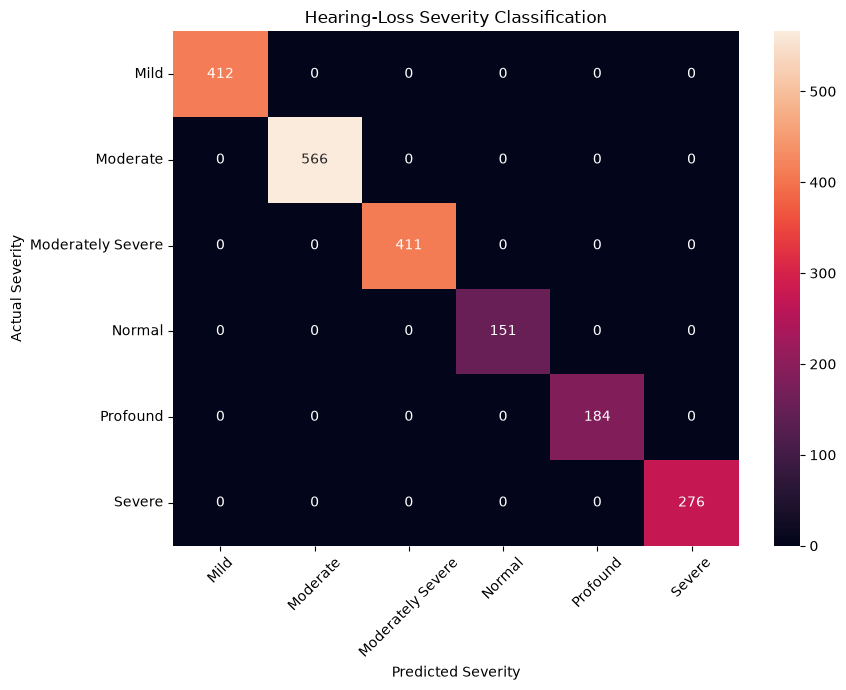

In [58]:
import matplotlib.pyplot as plt
import seaborn as sns

labels = sorted(y_test.unique())

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=labels,
    yticklabels=labels
)

plt.xlabel("Predicted Severity")
plt.ylabel("Actual Severity")
plt.title("Hearing-Loss Severity Classification")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


In [60]:
feature_names = preprocessor.get_feature_names_out()

importances = rf_model.feature_importances_

feature_importance = pd.DataFrame({
    "feature": feature_names,
    "importance": importances
}).sort_values(
    "importance",
    ascending=False
)

feature_importance.head(20)

,feature,importance
16,num__right_PTA4_dBHL,0.075679
34,num__left_PTA4_dBHL,0.071864
15,num__right_PTA3_dBHL,0.066908
33,num__left_PTA3_dBHL,0.064395
26,num__left_1000_AC_dBHL,0.043011
12,num__right_4000_AC_dBHL,0.041654
10,num__right_2000_AC_dBHL,0.037981
35,num__left_SRT_dBHL,0.036831
30,num__left_4000_AC_dBHL,0.035708
6,num__right_500_AC_dBHL,0.035587


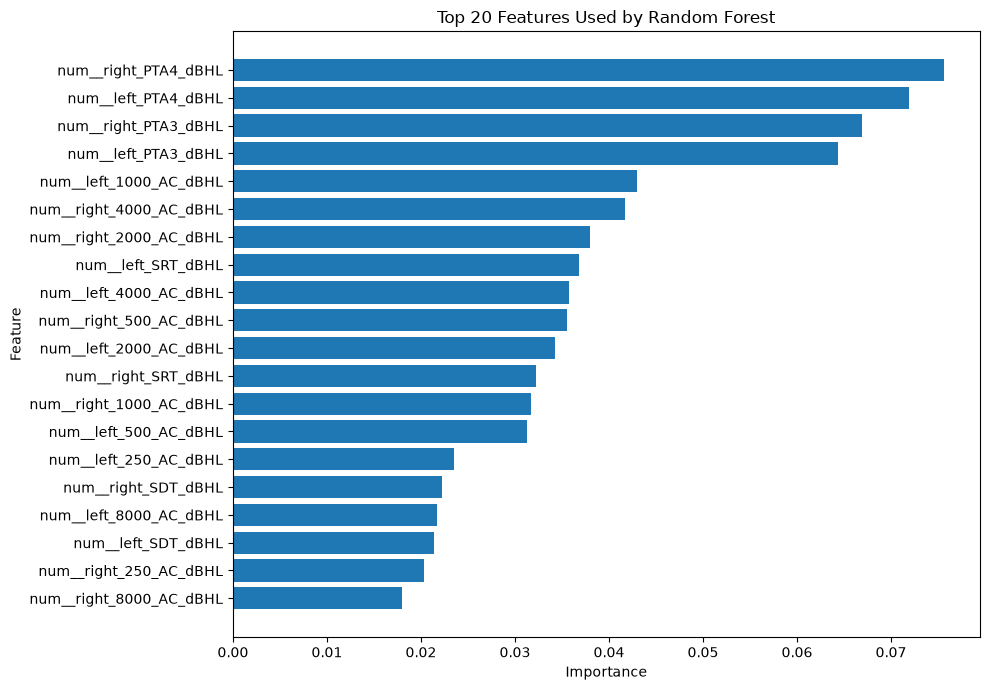

In [61]:
plt.figure(figsize=(10, 7))

top_features = feature_importance.head(20).sort_values("importance")

plt.barh(
    top_features["feature"],
    top_features["importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 20 Features Used by Random Forest")
plt.tight_layout()
plt.show()